# 05 — Baseline Models

Stage 06. Evaluates two parameter-free baselines under the Stage 04 protocol:
- **Persistence:** ŷ(t+1) = pm(t)
- **Seasonal-naive (24 h):** ŷ(t+1) = pm(t+1−24) = pm(t−23). The 24 h period comes from the daily cycle (Stage 03); the weekly lag has ACF ≈ 0.02 and was not considered.

All scores use the **common eval set**. **The 2014 test year is not scored here**; it is scored once, in Stage 08, together with XGBoost, so that no test result is seen before model development is finished.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import acf

from src.data import load_raw, validate
from src.features import build_dataset
from src import baselines as B, evaluate as E, protocol as P
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
X, y, split, mask = build_dataset(df)
pm = df['pm25']
preds = {'persistence': B.persistence(pm), 'seasonal_naive_24h': B.seasonal_naive(pm)}
SPLITS = ['train', 'val']   # test held out until Stage 08

## 1. Consistency checks

In [2]:
assert preds['persistence'].equals(X['pm_lag0'].rename('persistence'))
sn = preds['seasonal_naive_24h']
assert ((sn == X['pm_lag23']) | (sn.isna() & X['pm_lag23'].isna())).all()
for p in preds.values(): assert p[mask].notna().all()      # defined on every scored row
print('baselines match the lag features and are defined on the whole common eval set')

baselines match the lag features and are defined on the whole common eval set


## 2. Metrics by split (common eval set)

In [3]:
by_split = E.score_by_split(y, preds, split, mask, SPLITS)
by_split.round(3)

,model,split,n,MAE,RMSE,R2
0,persistence,train,23452,13.083,24.822,0.923
1,persistence,val,8563,13.184,24.870,0.936
2,seasonal_naive_24h,train,23452,67.526,98.774,-0.222
3,seasonal_naive_24h,val,8563,76.079,110.183,-0.260


## 3. Metrics by validation fold (the Stage 07 tuning folds)
These per-quarter scores are the reference XGBoost must be compared against in Stage 07.

In [4]:
val_folds = P.backtest_folds('2013-01-01', '2013-12-31 23:00', freq='QS')
by_fold = E.score_by_fold(y, preds, mask, val_folds)
by_fold.pivot(index=['fold', 'test_start', 'test_end'], columns='model', values=['MAE', 'RMSE', 'R2']).round(2)

MAE                           RMSE  \
model                      persistence seasonal_naive_24h persistence   
fold test_start test_end                                                
1    2013-01-01 2013-03-31       17.91             119.90       35.76   
2    2013-04-01 2013-06-30       11.66              56.92       19.52   
3    2013-07-01 2013-09-30        9.17              44.32       15.30   
4    2013-10-01 2013-12-31       14.05              83.64       24.23   

                                                       R2                     
model                      seasonal_naive_24h persistence seasonal_naive_24h  
fold test_start test_end                                                      
1    2013-01-01 2013-03-31             158.92        0.93              -0.33  
2    2013-04-01 2013-06-30              78.50        0.91              -0.49  
3    2013-07-01 2013-09-30              58.32        0.91              -0.25  
4    2013-10-01 2013-12-31             117.78        0.94              -0.42

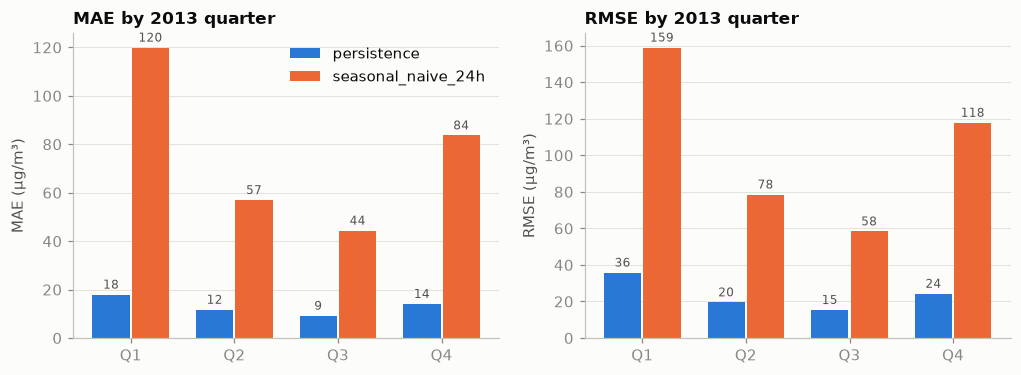

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
names = list(preds); w = 0.38; x = np.arange(len(val_folds))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    for i, n in enumerate(names):
        v = by_fold[by_fold.model == n][metric].values
        bars = ax.bar(x + (i - 0.5) * w, v, width=w - 0.02, color=ps.SERIES[i], label=n)
        ax.bar_label(bars, fmt='%.0f', fontsize=8, color=ps.INK_2, padding=2)
    ax.set_xticks(x, ['Q1', 'Q2', 'Q3', 'Q4'])
    ax.set(title=f'{metric} by 2013 quarter', ylabel=f'{metric} (µg/m³)'); ax.grid(axis='x', visible=False)
axes[0].legend(loc='upper right')
ps.save(fig, 'baselines_01_val_folds'); plt.show()

## 4. Why seasonal-naive has negative R²
For a stationary series with variance σ² and lag-*k* autocorrelation ρₖ, the naive forecast ŷ(t+k) = x(t) has MSE = E[(x(t+k) − x(t))²] = 2σ²(1 − ρₖ), so **R² ≈ 1 − 2(1 − ρₖ) = 2ρₖ − 1**. R² is negative whenever ρₖ < 0.5. With ρ₂₄ ≈ 0.39, copying yesterday's value is worse than predicting the mean, even though a daily cycle exists: the cycle is small compared with day-to-day changes in the pollution level.

In [6]:
tr = mask & (split == 'train')
rho = acf(pm[(split == 'train')], nlags=24, missing='conservative')
pd.DataFrame({'ρ (train ACF)': [rho[1], rho[24]],
              'R² predicted = 2ρ − 1': [2 * rho[1] - 1, 2 * rho[24] - 1],
              'R² observed (train)': by_split.set_index(['model', 'split']).loc[[('persistence', 'train'), ('seasonal_naive_24h', 'train')], 'R2'].values},
             index=['persistence (lag 1)', 'seasonal-naive (lag 24)']).round(3)

,ρ (train ACF),R² predicted = 2ρ − 1,R² observed (train)
persistence (lag 1),0.954,0.908,0.923
seasonal-naive (lag 24),0.384,-0.231,-0.222


## 5. Where does persistence fail? (validation)
Errors by the level of the true PM2.5 and by season. Validation rows only.

In [7]:
v = mask & (split == 'val')
err = (preds['persistence'] - y)[v]
lvl = pd.cut(y[v], [0, 35, 75, 150, 250, 1000], labels=['0–35', '35–75', '75–150', '150–250', '>250'], include_lowest=True)
t = pd.DataFrame({'hours': err.groupby(lvl, observed=True).size(), 'MAE': err.abs().groupby(lvl, observed=True).mean(),
                  'RMSE': err.pow(2).groupby(lvl, observed=True).mean().pow(0.5)})
t['share of squared error %'] = 100 * err.pow(2).groupby(lvl, observed=True).sum() / err.pow(2).sum()
t.round(1)

,hours,MAE,RMSE,share of squared error %
pm25_t+1,,,,
0–35,2355,6.0,14.1,8.8
35–75,2107,11.2,19.9,15.7
75–150,2227,14.2,22.4,21.1
150–250,1145,19.8,33.9,24.8
>250,729,28.7,46.3,29.5


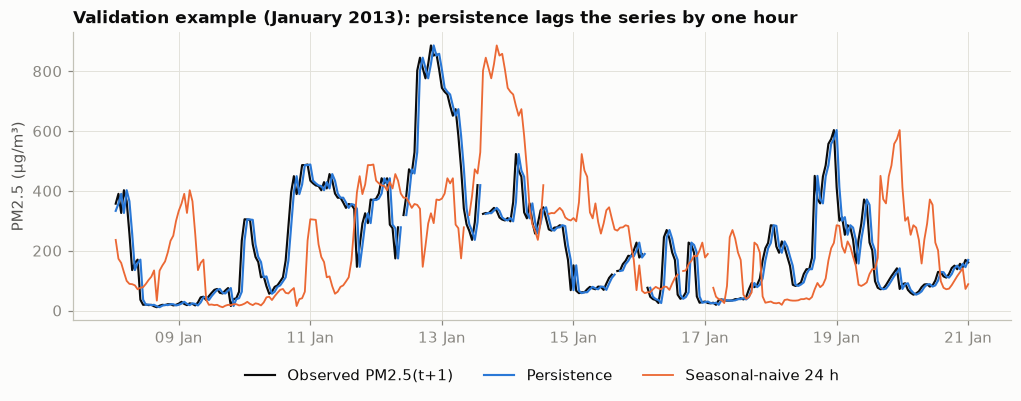

In [8]:
ep = slice('2013-01-08', '2013-01-20')
tt = y[ep].index + pd.Timedelta(hours=1)   # plot against the target hour
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tt, y[ep], color=ps.INK, linewidth=1.4, label='Observed PM2.5(t+1)')
ax.plot(tt, preds['persistence'][ep], color=ps.SERIES[0], linewidth=1.4, label='Persistence')
ax.plot(tt, preds['seasonal_naive_24h'][ep], color=ps.SERIES[1], linewidth=1.2, label='Seasonal-naive 24 h')
ax.set(title='Validation example (January 2013): persistence lags the series by one hour', ylabel='PM2.5 (µg/m³)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
ps.save(fig, 'baselines_02_val_example'); plt.show()

## 6. Save predictions and metrics
Predictions for train and validation issuance times (test rows are not written). Metrics go to `results/metrics/`.

In [9]:
out = pd.DataFrame({'target_time': y.index + pd.Timedelta(hours=1), 'split': split, 'in_eval_set': mask,
                    'y_true': y, **{n: p for n, p in preds.items()}})
out = out[out.split.isin(SPLITS)]
pred_dir = E.RESULTS_DIR / 'predictions'; pred_dir.mkdir(exist_ok=True)
out.to_csv(pred_dir / 'baselines_train_val.csv', index_label='issue_time')
by_split.to_csv(E.RESULTS_DIR / 'metrics' / 'baselines_by_split.csv', index=False)
by_fold.to_csv(E.RESULTS_DIR / 'metrics' / 'baselines_val_folds.csv', index=False)
print(len(out), 'prediction rows written; splits:', sorted(out.split.unique()))

35063 prediction rows written; splits: ['train', 'val']


In [10]:
# reproducibility: reload and re-score from the saved file
saved = pd.read_csv(pred_dir / 'baselines_train_val.csv', parse_dates=['issue_time']).set_index('issue_time')
s = saved[saved.in_eval_set & (saved.split == 'val')]
for n in preds:
    a = E.metrics(s.y_true, s[n]); b = by_split.set_index(['model', 'split']).loc[(n, 'val')]
    assert np.isclose(a['MAE'], b.MAE) and np.isclose(a['RMSE'], b.RMSE) and np.isclose(a['R2'], b.R2)
print('metrics reproduced from saved predictions')

metrics reproduced from saved predictions


## 7. Findings
- **Persistence is a strong baseline:** validation MAE 13.2, RMSE 24.9 µg/m³, R² 0.936. Its errors grow with the pollution level: hours with true PM2.5 > 150 µg/m³ are 22% of validation hours but 54% of the squared error (section 5).
- **Seasonal-naive (24 h) is poor:** validation MAE 76.1, RMSE 110.2, R² −0.26, i.e. worse than predicting the mean. This matches the theory R² ≈ 2ρ₂₄ − 1 with ρ₂₄ ≈ 0.39.
- **Persistence quality varies by season:** validation-fold MAE ranges from 9.2 (Q3) to 17.9 (Q1).
- **The bar for XGBoost is persistence**, not seasonal-naive. Any XGBoost gain must be judged against MAE ≈ 13 and RMSE ≈ 25 on the same rows.